80 атомов GAD, 128 фосфатов
средняя глубина |Z|: 5.25 ± 3.15 нм
доля времени в верхнем листке: 0.82
число смен листка (flip-flop): 211
доля времени в воде (за плоскостью P): 0.00
средний |Z| 1-я/2-я половина: 6.31401356533983 4.1864316808122695


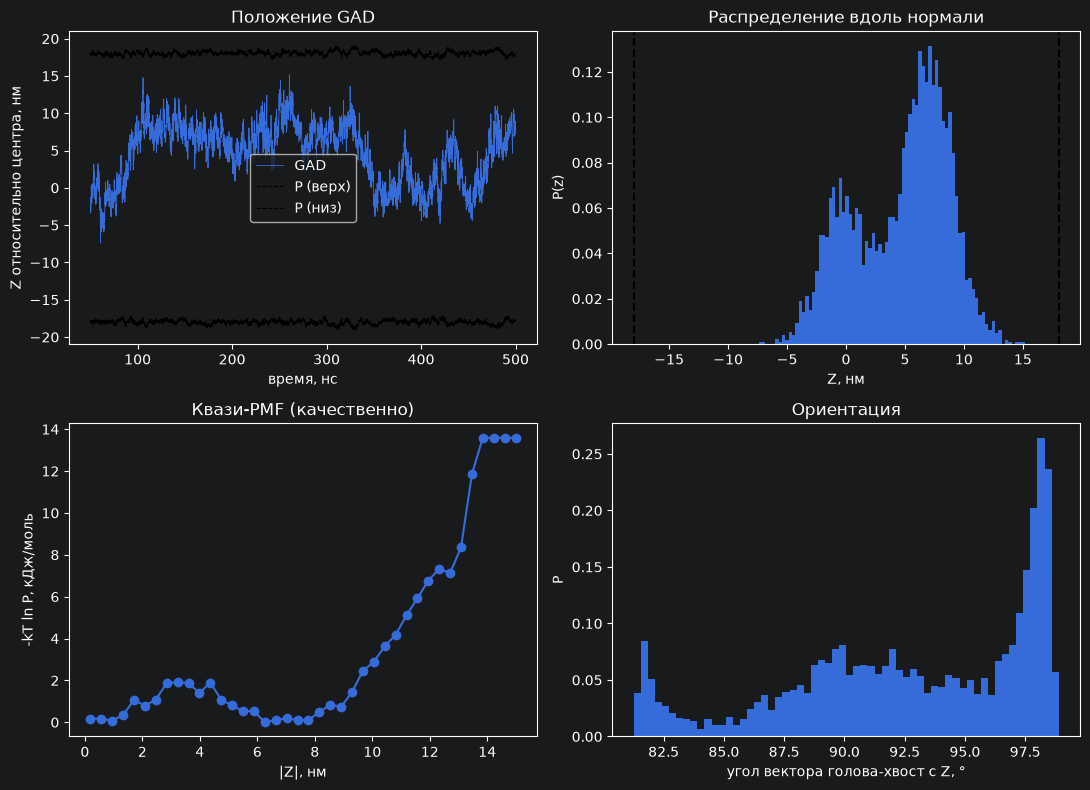

In [5]:
import numpy as np
import MDAnalysis as mda
import matplotlib.pyplot as plt

# ---------- параметры ----------
TOP, TRJ = 'step7_1.tpr', 'step7_no-jump-center.xtc'
SKIP_PS  = 50000        # отбросить первые 50 нс
LIG      = 'resname GAD'
# Атомы для вектора ориентации: подставьте имена из своего mol2/pdb
# (O 3-OH и C карбоксила), проверьте: u.select_atoms('resname GAD and name O*').names
A_HEAD, A_TAIL = 'O1', 'C30'
# --------------------------------

u = mda.Universe(TOP, TRJ)
lig   = u.select_atoms(LIG)
memb  = u.select_atoms('resname DMPC')
phos  = u.select_atoms('resname DMPC and name P')
head  = u.select_atoms(f'{LIG} and name {A_HEAD}')
tail  = u.select_atoms(f'{LIG} and name {A_TAIL}')
carbox = u.select_atoms(f'{LIG} and name O*')   # при необходимости сузьте до карбоксила

print(lig.n_atoms, 'атомов GAD,', phos.n_atoms, 'фосфатов')
assert head.n_atoms == 1 and tail.n_atoms == 1, 'проверьте имена атомов A_HEAD / A_TAIL'

rows = []
for ts in u.trajectory:
    if ts.time < SKIP_PS:
        continue
    zc   = memb.center_of_mass()[2]           # центр бислоя
    zp   = phos.positions[:, 2] - zc
    zup  = zp[zp > 0].mean()                  # плоскость фосфатов верхнего листка
    zlow = zp[zp < 0].mean()                  # нижнего
    zl   = lig.center_of_mass()[2] - zc       # глубина центра GAD
    zh   = head.positions[0, 2] - zc
    zt   = tail.positions[0, 2] - zc
    v    = tail.positions[0] - head.positions[0]
    cos  = v[2] / np.linalg.norm(v)           # косинус угла с нормалью Z
    rows.append((ts.time, zl, zh, zt, zup, zlow, cos))

d = np.array(rows)
t, zl, zh, zt, zup, zlow, cos = d.T
t_ns = t / 1000

# глубина относительно ближайшей плоскости фосфатов: 0 = на уровне фосфатов,
# отрицательно = глубже в гидрофобную область, положительно = в воде
leaflet = np.sign(zl)
dist_P  = np.where(leaflet > 0, zl - zup, -(zl - zlow))
np.savetxt('gad_depth.dat', np.c_[t_ns, zl, dist_P, leaflet, cos],
           header='t_ns z_nm dist_to_P_nm leaflet cos_theta')

# ---------- графики ----------
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

ax[0,0].plot(t_ns, zl, lw=.6, label='GAD')
ax[0,0].plot(t_ns, zup,  'k--', lw=.8, label='P (верх)')
ax[0,0].plot(t_ns, zlow, 'k--', lw=.8, label='P (низ)')
ax[0,0].set(xlabel='время, нс', ylabel='Z относительно центра, нм', title='Положение GAD')
ax[0,0].legend()

ax[0,1].hist(zl, bins=80, density=True)
for z in (zup.mean(), zlow.mean()): ax[0,1].axvline(z, color='k', ls='--')
ax[0,1].set(xlabel='Z, нм', ylabel='P(z)', title='Распределение вдоль нормали')

kT = 0.0083145 * 303.15
h, e = np.histogram(np.abs(zl), bins=40, density=True)
c = 0.5*(e[1:] + e[:-1])
with np.errstate(divide='ignore'):
    pmf = -kT*np.log(h)
pmf -= pmf[np.isfinite(pmf)].min()
ax[1,0].plot(c, pmf, 'o-')
ax[1,0].set(xlabel='|Z|, нм', ylabel='-kT ln P, кДж/моль', title='Квази-PMF (качественно)')

ax[1,1].hist(np.degrees(np.arccos(cos)), bins=60, density=True)
ax[1,1].set(xlabel='угол вектора голова-хвост с Z, °', ylabel='P', title='Ориентация')

plt.tight_layout(); plt.savefig('gad_localization.png', dpi=200)

# ---------- сводка ----------
print(f'средняя глубина |Z|: {np.abs(zl).mean():.2f} ± {np.abs(zl).std():.2f} нм')
print(f'доля времени в верхнем листке: {(leaflet>0).mean():.2f}')
print(f'число смен листка (flip-flop): {(np.diff(leaflet)!=0).sum()}')
print(f'доля времени в воде (за плоскостью P): {(dist_P>0).mean():.2f}')
# сходимость: две половины траектории
n = len(zl)//2
print('средний |Z| 1-я/2-я половина:', np.abs(zl[:n]).mean(), np.abs(zl[n:]).mean())